# Resultados finales: predicción paralela de mapas de calor (LST) en Tlaxcala y Puebla

**Tercer avance.** Se entrena con 2016–2023 y se predicen los **12 mapas de 2024**, un año que el modelo nunca vio, y se compara contra tres referencias sencillas.

**Paralelismo (multiprocessing, sin joblib ni n_jobs):**
1. Construcción de la tabla pixel-mes con memoria compartida (paralelismo de datos).
2. Búsqueda de hiperparámetros de KNN, RF y SVR (paralelización exploratoria, reparto estático vs. dinámico).
3. Predicción de los mapas de 2024 por bloques de pixeles (paralelismo de datos).

In [1]:
import os
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v] = "1"          # cada proceso usa un solo hilo: el paralelismo lo controlamos nosotros

import ast
import time
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import datos
import modelos
import paralelo as par

RUTA_LST = os.environ.get("RUTA_LST", "LST_mensual.tif")
RUTA_NDVI = os.environ.get("RUTA_NDVI", "NDVI_mensual.tif")
RUTA_ALT = os.environ.get("RUTA_ALT", "ALTITUD.tif")
ANIO_PRUEBA = 2024
N_MAX_ENTRENAMIENTO = int(os.environ.get("N_MAX", 40000))
REPETIR_BUSQUEDA = False   # True = volver a correr las 46 combinaciones (≈40 min con 8 núcleos)
NUCLEOS = mp.cpu_count()
LISTA_PROCESOS = [p for p in [1, 2, 4, 8, 16] if p <= NUCLEOS]

os.makedirs("resultados", exist_ok=True)
os.makedirs("figuras", exist_ok=True)
COLORES = {"KNN": "#2a78d6", "RF": "#eb6834", "SVR": "#1baf7a",
           "Persistencia_t1": "#9a9a9a", "Persistencia_t12": "#6b6b6b", "Climatologia": "#3d3d3d"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
print("Núcleos:", NUCLEOS, "| Procesos a medir:", LISTA_PROCESOS)

Núcleos: 8 | Procesos a medir: [1, 2, 4, 8]


## 1. Lectura de los mapas mensuales

In [2]:
mapas = datos.leer_mapas(RUTA_LST, RUTA_NDVI, RUTA_ALT)
lst, ndvi, alt, lat, lon = mapas
FORMA = alt.shape
EXTENSION = [lon[0], lon[-1], lat[-1], lat[0]]

Mapas: 120 meses de 329 x 261 pixeles


## 2. Construcción de la tabla en paralelo: versión del 2º avance vs. versión final

En el 2º avance, 8 procesos tardaban **más** que 1: cada proceso recibía una copia de los mapas y regresaba su bloque de la tabla serializado, y unir los bloques costaba más que armarlos.

La versión final (`datos.construir_variables`) pone los mapas y la tabla de salida en **memoria compartida**:
- **Fase 1:** cada proceso cuenta los registros válidos de su bloque de filas.
- **Suma prefija:** el proceso principal calcula dónde escribe cada bloque.
- **Fase 2:** cada proceso escribe sus registros directamente en la tabla compartida.

Se verifica que las dos versiones producen exactamente la misma tabla.

In [3]:
tiempos_v1, tiempos_v2 = {}, {}
for p in LISTA_PROCESOS:
    df_v1, tiempos_v1[p] = datos.construir_variables_v1(mapas, procesos=p)
    df, tiempos_v2[p] = datos.construir_variables(mapas, procesos=p)
    print(f"{p:>2} procesos:  v1 {tiempos_v1[p]:6.2f} s   v2 {tiempos_v2[p]:6.2f} s   ({len(df):,} filas)")

# Las dos versiones deben dar la misma tabla
cols = list(df_v1.columns)
dif = max(float(np.abs(df_v1[c].to_numpy(float) - df[c].to_numpy(float)).max()) for c in cols)
print("Misma tabla:", df_v1.shape == df[cols].shape, "| diferencia máxima =", dif)
del df_v1

tabla_v1 = par.metricas_paralelas(tiempos_v1).assign(version="v1 (2º avance)")
tabla_v2 = par.metricas_paralelas(tiempos_v2).assign(version="v2 (memoria compartida)")
construccion = pd.concat([tabla_v1, tabla_v2], ignore_index=True)
construccion.to_csv("resultados/construccion_tabla_v1_vs_v2.csv", index=False)
construccion.round(3)

 1 procesos:  v1  35.65 s   v2   4.20 s   (4,429,724 filas)
 2 procesos:  v1  28.11 s   v2   8.58 s   (4,429,724 filas)
 4 procesos:  v1  26.25 s   v2   8.31 s   (4,429,724 filas)
 8 procesos:  v1  39.76 s   v2   8.56 s   (4,429,724 filas)
Misma tabla: True | diferencia máxima = 0.0


,procesos,tiempo_s,speedup,eficiencia,karp_flatt,version
0,1,35.647,1.000,1.000,NaN,v1 (2º avance)
1,2,28.111,1.268,0.634,0.577,v1 (2º avance)
2,4,26.253,1.358,0.339,0.649,v1 (2º avance)
3,8,39.756,0.897,0.112,1.132,v1 (2º avance)
4,1,4.202,1.000,1.000,NaN,v2 (memoria compartida)
5,2,8.581,0.490,0.245,3.084,v2 (memoria compartida)
6,4,8.312,0.506,0.126,2.304,v2 (memoria compartida)
7,8,8.560,0.491,0.061,2.185,v2 (memoria compartida)


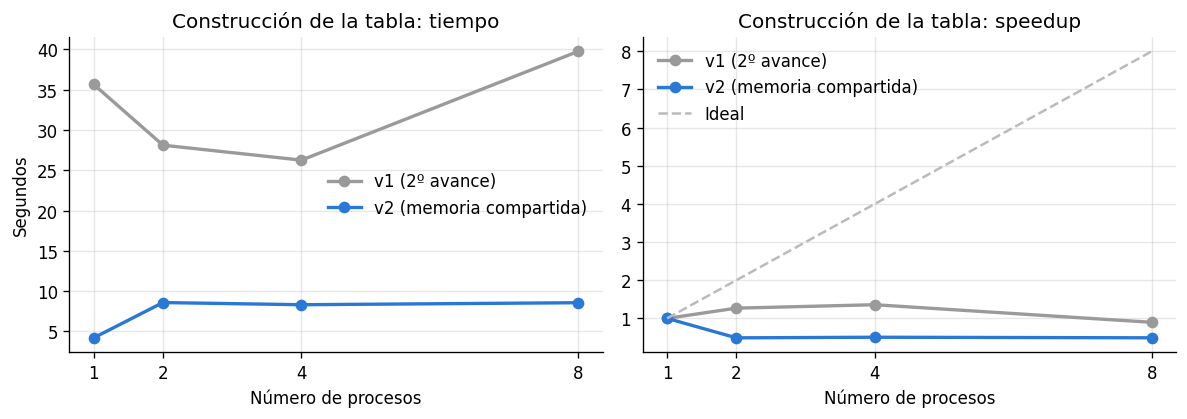

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for t, color in ((tabla_v1, "#9a9a9a"), (tabla_v2, "#2a78d6")):
    axes[0].plot(t["procesos"], t["tiempo_s"], marker="o", lw=2, color=color, label=t["version"][0])
    axes[1].plot(t["procesos"], t["speedup"], marker="o", lw=2, color=color, label=t["version"][0])
axes[1].plot(LISTA_PROCESOS, LISTA_PROCESOS, ls="--", color="#bbbbbb", label="Ideal")
axes[0].set_title("Construcción de la tabla: tiempo"); axes[0].set_ylabel("Segundos")
axes[1].set_title("Construcción de la tabla: speedup"); axes[1].legend(frameon=False)
for ax in axes:
    ax.set_xlabel("Número de procesos"); ax.set_xticks(LISTA_PROCESOS)
axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig("figuras/construccion_tabla_v1_vs_v2.png", dpi=200); plt.show()

In [5]:
resumen_datos = pd.DataFrame({"dato": ["Filas (pixel-mes)", "Pixeles con datos", "Meses", "Años"],
    "valor": [len(df), df.groupby(["fila", "col"]).ngroups, df[["anio", "mes"]].drop_duplicates().shape[0],
              f"{df['anio'].min()}–{df['anio'].max()}"]})
resumen_datos.to_csv("resultados/resumen_datos.csv", index=False)
resumen_datos

,dato,valor
0,Filas (pixel-mes),4429724
1,Pixeles con datos,41050
2,Meses,108
3,Años,2016–2024
